# 01 · Exploração dos dados (Case NPS, Tech Challenge Fase 1)

**Objetivo:** entender a base antes de definir o alvo e o modelo. Cada bloco traz a observação, a hipótese que ela sugere e o limite dessa hipótese.

**Problema de negócio:** a empresa cresceu e passou a processar muito mais pedidos, entregas e atendimentos. O NPS varia entre clientes com indicadores operacionais parecidos, e não se sabe quais fatores operacionais explicam essa diferença. Como o NPS só é coletado no fim da jornada, a empresa descobre o problema depois que o cliente já ficou insatisfeito.

**Como rodar:** execute as células em ordem. O CSV está em `data/01_raw/desafio_nps_fase_1.csv`.


## 0. Preparação

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from src.analise import contar_outliers_iqr


In [2]:
# Arquivo CSV do desafio
CAMINHO_DADOS = '../data/01_raw/desafio_nps_fase_1.csv'

df = pd.read_csv(CAMINHO_DADOS)
df.head()

,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


## 1. Quantas linhas e colunas existem, e de que tipo?
**Por que olhar isso primeiro:** antes de qualquer análise, confira o tamanho da base e o tipo de cada coluna, número ou texto.


In [3]:
df.shape

(2500, 19)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                2500 non-null   int64  
 1   customer_age               2500 non-null   int64  
 2   customer_region            2500 non-null   str    
 3   customer_tenure_months     2500 non-null   int64  
 4   order_id                   2500 non-null   int64  
 5   order_value                2500 non-null   float64
 6   items_quantity             2500 non-null   int64  
 7   discount_value             2500 non-null   float64
 8   payment_installments       2500 non-null   int64  
 9   delivery_time_days         2500 non-null   int64  
 10  delivery_delay_days        2500 non-null   int64  
 11  freight_value              2500 non-null   float64
 12  delivery_attempts          2500 non-null   int64  
 13  customer_service_contacts  2500 non-null   int64  
 14  res

**Observação:** a base tem 2.500 linhas e 19 colunas. 18 colunas são numéricas e 1 é texto (`customer_region`). Cada `customer_id` e cada `order_id` aparece uma única vez.

**Hipótese:** a base tem um pedido por cliente. `customer_id` e `order_id` aparecem uma vez por linha, então não há histórico do mesmo cliente ao longo do tempo.

**Limite da hipótese:** a base não tem coluna de data. Não dá para dizer se o NPS melhorou ou piorou com o tempo, nem se o problema cresce com o número de clientes.


### 1.1 O que esta base não conta
Antes de seguir, vale registrar o que o dataset não mostra. Nenhum dataset é um retrato completo da realidade, e a parte que falta também faz parte da história.

- Não há coluna de data. Não dá para saber o período coberto, um mês, um ano ou vários, nem se os padrões mudam com o tempo.
- A coluna `nps_score` não tem nenhum valor ausente (confirmado na seção 2). É possível que a base já esteja filtrada só para os clientes que responderam a pesquisa de NPS. Se clientes insatisfeitos respondem a pesquisa mais ou menos que os satisfeitos, o retrato geral muda.
- Não há coluna de canal de aquisição, campanha de marketing ou produto comprado. Não dá para saber se os padrões encontrados valem para toda a operação ou só para um recorte dela.
- Não se sabe se a base representa todos os pedidos da empresa, ou uma amostra.

Essas lacunas não impedem a análise, mas limitam até onde as conclusões valem fora deste recorte específico.


## 2. Há valores ausentes ou linhas repetidas?
**Por que importa:** ausentes e duplicados distorcem médias e correlações. É o primeiro ponto a descartar antes de qualquer leitura.


In [5]:
df.isnull().sum()

customer_id                  0
customer_age                 0
customer_region              0
customer_tenure_months       0
order_id                     0
order_value                  0
items_quantity               0
discount_value               0
payment_installments         0
delivery_time_days           0
delivery_delay_days          0
freight_value                0
delivery_attempts            0
customer_service_contacts    0
resolution_time_days         0
nps_score                    0
repeat_purchase_30d          0
complaints_count             0
csat_internal_score          0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

**Observação:** nenhuma coluna tem valor ausente e não há linhas duplicadas.

**Hipótese:** não é preciso tratar ausentes nem remover duplicados.

**Limite da hipótese:** que os dados estão corretos. Não ter vazios não garante que os valores façam sentido (veja a seção 8).


## 3. Como são as variáveis numéricas, em resumo?
**Por que importa:** o resumo (mínimo, mediana, máximo) mostra a escala de cada variável e já aponta valores estranhos.


In [7]:
df.describe()

,customer_id,customer_age,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
count,2500.00000,2500.000000,2500.000000,2500.00000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,1250.50000,43.396000,61.322400,51250.50000,434.259740,3.470800,29.745620,6.004000,8.022000,2.187200,38.217016,2.005600,1.519600,5.485600,4.378600,0.087200,4.150400,2.941600
std,721.83216,14.888487,34.478729,721.83216,289.772497,1.687331,29.225603,3.159743,3.770411,1.454442,12.076074,0.815497,1.231512,3.458002,2.510229,0.282184,1.784223,2.378957
min,1.00000,18.000000,1.000000,50001.00000,7.760000,1.000000,0.020000,1.000000,2.000000,0.000000,2.620000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,625.75000,31.000000,31.000000,50625.75000,220.245000,2.000000,8.885000,3.000000,5.000000,1.000000,29.927500,1.000000,1.000000,2.000000,2.600000,0.000000,3.000000,0.700000
50%,1250.50000,43.000000,62.000000,51250.50000,375.515000,3.000000,20.935000,6.000000,8.000000,2.000000,38.500000,2.000000,1.000000,6.000000,4.400000,0.000000,4.000000,2.800000
75%,1875.25000,56.000000,91.000000,51875.25000,577.290000,5.000000,40.832500,9.000000,11.000000,3.000000,46.270000,3.000000,2.000000,8.000000,6.100000,0.000000,5.000000,4.800000
max,2500.00000,69.000000,119.000000,52500.00000,1983.810000,6.000000,230.330000,11.000000,14.000000,8.000000,76.130000,3.000000,7.000000,11.000000,10.000000,1.000000,11.000000,10.000000


**Observação:**
- Valor do pedido: de 7,8 a 1.983,8 (mediana 375,5)
- Desconto: de 0 a 230,3 (mediana 20,9)
- Prazo estimado de entrega: de 2 a 14 dias
- Atraso: de 0 a 8 dias
- Reclamações: de 0 a 11
- Contatos com o atendimento: de 0 a 7
- Tempo de resolução: de 0 a 11 dias
- Nota de NPS: de 0 a 10

**Hipótese:** as escalas são muito diferentes entre as colunas. O valor do pedido fica em centenas, o atraso fica em poucos dias. Isso importa ao comparar o peso de cada variável.

**Limite da hipótese:** nada sobre causas. O resumo só descreve.


## 4. Como está distribuída a nota de NPS (o alvo)?
**Por que importa:** o alvo do projeto é a nota de NPS (`nps_score`). Confira se ela se concentra em algum ponto, se há acúmulos em 0 e 10, e se é inteira ou decimal.


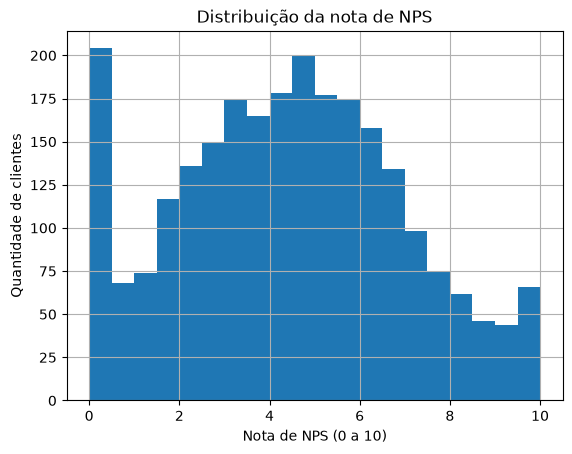

In [8]:
df['nps_score'].hist(bins=20)
plt.title('Distribuição da nota de NPS')
plt.xlabel('Nota de NPS (0 a 10)')
plt.ylabel('Quantidade de clientes')
plt.show()

In [9]:
df['nps_score'].describe()

count    2500.000000
mean        4.378600
std         2.510229
min         0.000000
25%         2.600000
50%         4.400000
75%         6.100000
max        10.000000
Name: nps_score, dtype: float64

In [10]:
zeros = (df['nps_score'] == 0.0).sum()
dez = (df['nps_score'] == 10.0).sum()
entre_6_7 = ((df['nps_score'] > 6) & (df['nps_score'] < 7)).sum()
entre_8_9 = ((df['nps_score'] > 8) & (df['nps_score'] < 9)).sum()

print('Notas exatamente 0:', zeros)
print('Notas exatamente 10:', dez)
print('Notas entre 6 e 7 (ex: 6,5):', entre_6_7)
print('Notas entre 8 e 9 (ex: 8,5):', entre_8_9)

Notas exatamente 0: 158
Notas exatamente 10: 42
Notas entre 6 e 7 (ex: 6,5): 258
Notas entre 8 e 9 (ex: 8,5): 91


**Observação:** a nota média é 4,38 e a mediana é 4,4. Metade dos clientes deu nota até 4,4. Há 158 notas exatamente 0 e 42 notas exatamente 10. A nota tem casas decimais: 258 clientes têm nota entre 6 e 7 (por exemplo 6,5) e 91 têm nota entre 8 e 9, valores que não caem em nenhuma das faixas clássicas.

**Hipótese:** a nota é decimal e muitos clientes têm notas baixas. As faixas clássicas do NPS (detrator de 0 a 6, passivo 7 e 8, promotor 9 e 10) foram pensadas para notas inteiras. Elas deixam intervalos sem classificação quando a nota é decimal, por exemplo 6,5 ou 8,7.

**Limite da hipótese:** que a nota decimal tem a mesma leitura de uma nota inteira dada pelo cliente. A base não explica por que a nota tem casas decimais.


In [11]:
print('Notas exatamente 6,5:', (df['nps_score'] == 6.5).sum())
print('Notas exatamente 7,5:', (df['nps_score'] == 7.5).sum())
print('Notas exatamente 8,5:', (df['nps_score'] == 8.5).sum())

Notas exatamente 6,5: 26
Notas exatamente 7,5: 13
Notas exatamente 8,5: 8


### 4.1 Cálculo do NPS da empresa
**Decisão:** para encaixar as notas decimais nas faixas clássicas, a nota é arredondada para o inteiro mais próximo com o `.round()` do pandas, e depois classificada: 0 a 6 é detrator, 7 e 8 é passivo, 9 e 10 é promotor. O NPS é a porcentagem de promotores menos a porcentagem de detratores.

**Observação:** quando a nota termina em ,5, o `.round()` do pandas arredonda para o número par mais próximo (arredondamento bancário). 6,5 vira 6 (detrator), 7,5 vira 8 e 8,5 vira 8 (passivo). Na base, isso afeta 26 notas 6,5 e 8 notas 8,5.

A nota arredondada fica numa variável separada (`nota_arredondada`). A coluna `nps_score` não muda. Ela é o alvo do modelo.


In [12]:
# Arredonda a nota decimal para o inteiro mais próximo, só para classificar
nota_arredondada = df['nps_score'].round()

# Faixas clássicas de NPS: 0-6 detrator, 7-8 passivo, 9-10 promotor
detratores = (nota_arredondada <= 6).sum()
promotores = (nota_arredondada >= 9).sum()
passivos = df.shape[0] - detratores - promotores
total = df.shape[0]

print('Detratores:', detratores, f'({detratores/total*100:.1f}%)')
print('Passivos:', passivos, f'({passivos/total*100:.1f}%)')
print('Promotores:', promotores, f'({promotores/total*100:.1f}%)')


Detratores: 2001 (80.0%)
Passivos: 351 (14.0%)
Promotores: 148 (5.9%)


In [13]:
total = df.shape[0]

nps_empresa = (promotores / total - detratores / total) * 100

print('NPS da empresa:', round(nps_empresa, 1))

NPS da empresa: -74.1


In [14]:
n = len(df)

# Regra alternativa A: arredondar "meio para cima" em vez de arredondamento bancário
nota_meio_para_cima = np.floor(df['nps_score'] + 0.5)
det_a = (nota_meio_para_cima <= 6).sum()
pro_a = (nota_meio_para_cima >= 9).sum()
print('Regra "meio para cima": NPS =', round((pro_a - det_a) / n * 100, 1))

# Regra alternativa B: cortar direto na nota decimal, sem arredondar
det_b = (df['nps_score'] < 7).sum()
pro_b = (df['nps_score'] >= 9).sum()
print('Regra sem arredondar (abaixo de 7 é detrator): NPS =', round((pro_b - det_b) / n * 100, 1))

Regra "meio para cima": NPS = -72.8
Regra sem arredondar (abaixo de 7 é detrator): NPS = -80.0


**Observação:** com essa regra, são 2.001 detratores (80%), 351 passivos (14%) e 148 promotores (6%). O NPS da empresa é -74,1.

**Hipótese:** a grande maioria dos clientes é detratora. O resultado confirma o problema descrito no enunciado: a satisfação está muito baixa.

**Limite da hipótese:** que o número seria igual com outra regra. Arredondando "meio para cima" (6,5 vira 7), o NPS seria -72,8. Cortando sem arredondar, abaixo de 7 é detrator, o NPS seria -80,0. A conclusão de NPS muito negativo vale para as três regras.


## 5. Há valores muito fora do padrão (outliers)?
**Por que importa:** poucos valores muito altos podem puxar a média e atrapalhar a leitura. O boxplot mostra a mediana, a variação e os pontos fora do padrão.


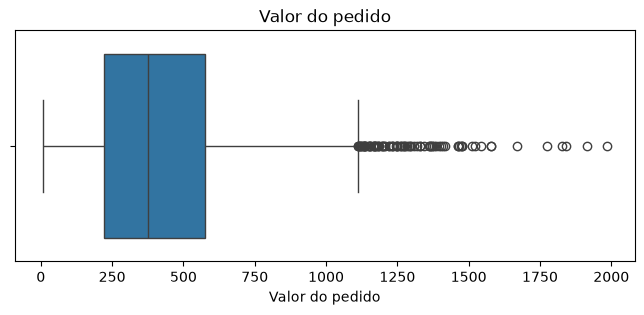

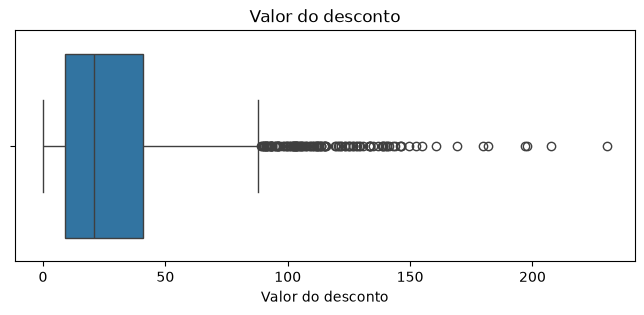

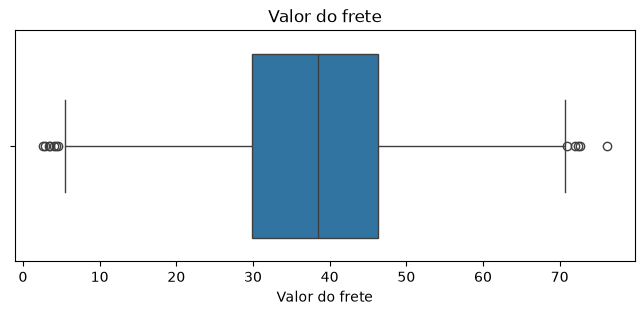

In [15]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df['order_value'])
plt.title('Valor do pedido')
plt.xlabel('Valor do pedido')
plt.show()

plt.figure(figsize=(8, 3))
sns.boxplot(x=df['discount_value'])
plt.title('Valor do desconto')
plt.xlabel('Valor do desconto')
plt.show()

plt.figure(figsize=(8, 3))
sns.boxplot(x=df['freight_value'])
plt.title('Valor do frete')
plt.xlabel('Valor do frete')
plt.show()

In [16]:
# contar_outliers_iqr vem de src/analise.py (regra do boxplot: fora de 1.5x o IQR)
print('Outliers em order_value:', contar_outliers_iqr(df['order_value']))
print('Outliers em discount_value:', contar_outliers_iqr(df['discount_value']))
print('Outliers em freight_value:', contar_outliers_iqr(df['freight_value']))


Outliers em order_value: 84
Outliers em discount_value: 125
Outliers em freight_value: 12


**Observação:** o valor do pedido tem 84 pontos acima do padrão do boxplot, o desconto tem 125 e o frete tem 12. O frete é a variável mais concentrada, de 2,6 a 76,1.

**Hipótese:** valor do pedido e desconto têm cauda longa, poucos valores muito altos. A mediana descreve melhor o pedido típico do que a média.

**Limite da hipótese:** que os valores altos são erros. Podem ser pedidos grandes legítimos. Nenhum valor é removido.


## 6. Como se comportam as variáveis de entrega e de atendimento?
**Por que importa:** são os fatores operacionais que o enunciado pede para investigar, logística e atendimento. Como são números inteiros, cada barra representa um valor exato.


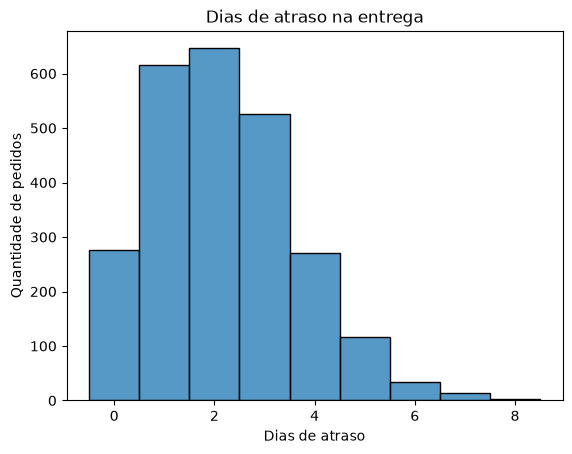

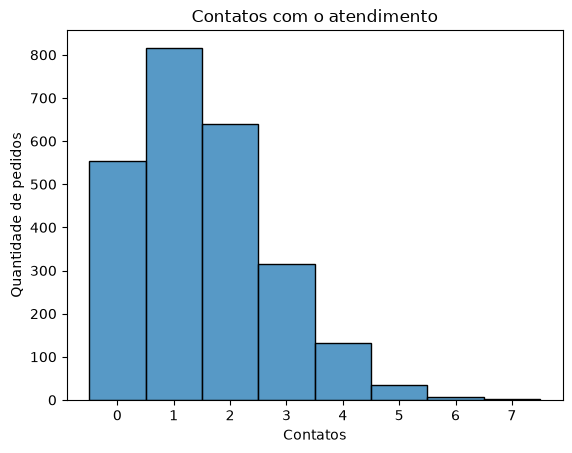

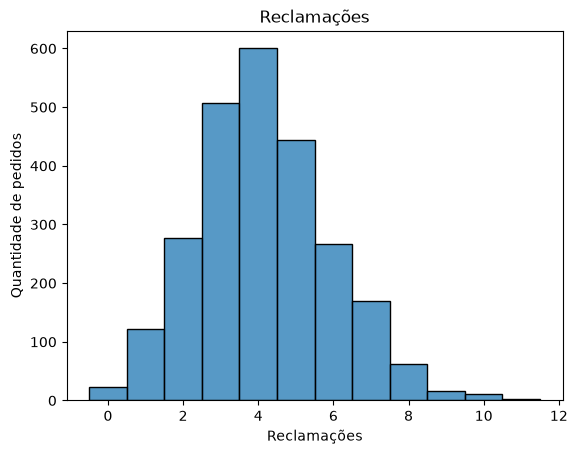

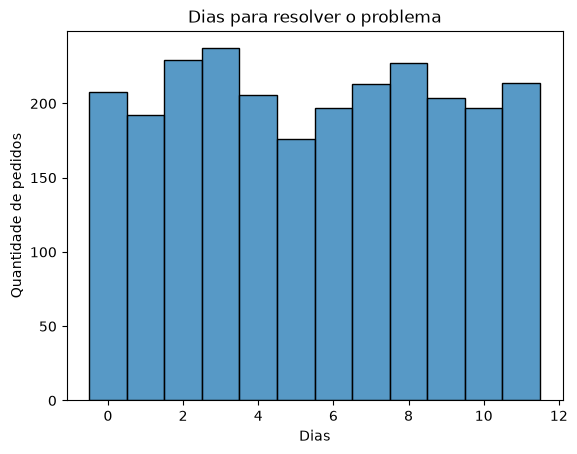

In [17]:
sns.histplot(data=df, x='delivery_delay_days', discrete=True)
plt.title('Dias de atraso na entrega')
plt.xlabel('Dias de atraso')
plt.ylabel('Quantidade de pedidos')
plt.show()

sns.histplot(data=df, x='customer_service_contacts', discrete=True)
plt.title('Contatos com o atendimento')
plt.xlabel('Contatos')
plt.ylabel('Quantidade de pedidos')
plt.show()

sns.histplot(data=df, x='complaints_count', discrete=True)
plt.title('Reclamações')
plt.xlabel('Reclamações')
plt.ylabel('Quantidade de pedidos')
plt.show()

sns.histplot(data=df, x='resolution_time_days', discrete=True)
plt.title('Dias para resolver o problema')
plt.xlabel('Dias')
plt.ylabel('Quantidade de pedidos')
plt.show()

In [18]:
print('Distribuição de dias de atraso:')
print(df['delivery_delay_days'].value_counts().sort_index())
print()
print('Pedidos com mais de 5 dias de atraso:', (df['delivery_delay_days'] > 5).sum())
print()
print('Distribuição de contatos com o atendimento:')
print(df['customer_service_contacts'].value_counts().sort_index())
print()
print('Distribuição de reclamações:')
print(df['complaints_count'].value_counts().sort_index())
print()
print('Pedidos por dias de resolução (resolution_time_days):')
print(df['resolution_time_days'].value_counts().sort_index())

Distribuição de dias de atraso:
delivery_delay_days
0    277
1    615
2    646
3    525
4    270
5    116
6     34
7     14
8      3
Name: count, dtype: int64

Pedidos com mais de 5 dias de atraso: 51

Distribuição de contatos com o atendimento:
customer_service_contacts
0    554
1    816
2    640
3    314
4    132
5     34
6      7
7      3
Name: count, dtype: int64

Distribuição de reclamações:
complaints_count
0      23
1     122
2     277
3     507
4     600
5     444
6     266
7     169
8      63
9      16
10     11
11      2
Name: count, dtype: int64

Pedidos por dias de resolução (resolution_time_days):
resolution_time_days
0     208
1     192
2     229
3     237
4     206
5     176
6     197
7     213
8     227
9     204
10    197
11    214
Name: count, dtype: int64


**Observação:** a maioria dos pedidos tem de 1 a 3 dias de atraso. Só 277 pedidos (11%) chegaram sem atraso, e poucos passam de 5 dias. Nos contatos, 554 pedidos não tiveram nenhum contato, e a maioria teve 1 ou 2. As reclamações se concentram entre 3 e 5 por pedido, e só 23 pedidos não têm reclamação. O tempo de resolução se espalha de forma quase igual entre 0 e 11 dias, cerca de 200 pedidos em cada valor.

**Hipótese:** atraso, contatos e reclamações têm formatos parecidos com o de contagens do dia a dia, muitos valores baixos e poucos altos. O tempo de resolução se espalha de forma quase uniforme, o que é incomum para esse tipo de medida. Vale lembrar isso na seção 8.

**Limite da hipótese:** por que os pedidos atrasaram. A base mostra quantos dias passaram do prazo, mas não o motivo.


## 7. O NPS muda conforme a região?
**Por que importa:** o enunciado pergunta que tipo de cliente tende a ter NPS mais alto ou mais baixo.


In [19]:
df.groupby('customer_region')['nps_score'].describe()

,count,mean,std,min,25%,50%,75%,max
customer_region,,,,,,,,
Centro-Oeste,468.0,4.209829,2.625968,0.0,2.100,4.2,6.1,10.0
Nordeste,485.0,4.421649,2.434829,0.0,2.700,4.5,6.1,10.0
Norte,506.0,4.382609,2.485931,0.0,2.600,4.5,6.1,10.0
Sudeste,520.0,4.373846,2.491552,0.0,2.575,4.3,6.1,10.0
Sul,521.0,4.490979,2.516739,0.0,2.700,4.5,6.3,10.0


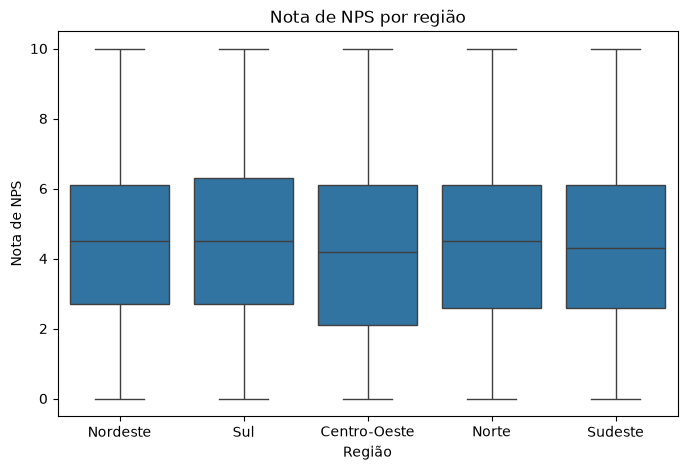

In [20]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='customer_region', y='nps_score')
plt.title('Nota de NPS por região')
plt.xlabel('Região')
plt.ylabel('Nota de NPS')
plt.show()

In [21]:
from scipy import stats

# Separa a nota de NPS em uma lista por região, uma entrada por grupo
grupos_por_regiao = [grupo['nps_score'].values for nome, grupo in df.groupby('customer_region')]

# ANOVA testa se as médias dos 5 grupos são iguais (H0) ou se pelo menos uma difere
resultado_anova = stats.f_oneway(*grupos_por_regiao)
print('F_estatistico:', round(resultado_anova.statistic, 3))
print('p_valor:', round(resultado_anova.pvalue, 3))


F_estatistico: 0.826
p_valor: 0.508


O boxplot e as médias dão uma primeira impressão, mas não confirmam se a diferença entre regiões é real ou só variação ao acaso. O teste ANOVA (análise de variância) compara as 5 médias de uma vez e responde isso.

**Observação:** o teste ANOVA dá F = 0,826 e p-valor = 0,508. Como o p-valor é maior que 0,05, não há evidência estatística de diferença entre as médias de NPS das regiões.

**Hipótese:** o teste confirma a leitura do boxplot. A região não explica a variação do NPS nesta base.

**Limite da hipótese:** que a região nunca importa para satisfação em outro contexto, nem que o teste prova ausência total de diferença, só que, com os dados disponíveis, não há evidência suficiente para rejeitar a hipótese de que as médias são iguais.


**Observação:** as médias por região ficam entre 4,21 (Centro-Oeste) e 4,49 (Sul), uma diferença de cerca de 0,3 ponto numa escala de 0 a 10. As cinco regiões têm entre 468 e 521 clientes. As caixas do boxplot se sobrepõem quase por inteiro.

**Hipótese:** a região, sozinha, explica pouco da diferença de NPS entre clientes.

**Limite da hipótese:** que a região causa a diferença de NPS.


## 8. Os dados fazem sentido entre si?
**Por que importa:** algumas combinações de colunas parecem estranhas. Nenhum dado é corrigido. As inconsistências ficam registradas como limitação, com a dúvida anotada.

Os três primeiros gráficos são mapas de calor com contagem: cada célula mostra quantos pedidos têm aquela combinação de valores, e quanto mais escura, mais pedidos. Essa escolha substitui o gráfico de pontos porque as variáveis são números inteiros, e os pontos se sobreporiam, escondendo a quantidade.


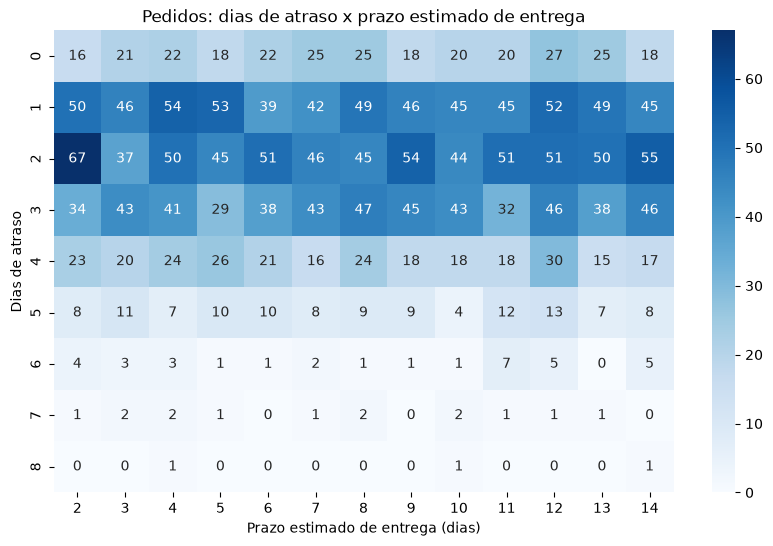

In [22]:
tabela_atraso = pd.crosstab(df['delivery_delay_days'], df['delivery_time_days'])

plt.figure(figsize=(10, 6))
sns.heatmap(tabela_atraso, annot=True, fmt="d", cmap="Blues")
plt.title('Pedidos: dias de atraso x prazo estimado de entrega')
plt.xlabel('Prazo estimado de entrega (dias)')
plt.ylabel('Dias de atraso')
plt.show()

In [23]:
print('Pedidos em que o atraso é maior que o prazo estimado:', (df['delivery_delay_days'] > df['delivery_time_days']).sum())

Pedidos em que o atraso é maior que o prazo estimado: 121


**O que olhar:** o dicionário descreve `delivery_time_days` como tempo total de entrega. Se fosse o tempo total, o atraso faria parte dele e nunca poderia ser maior. Pelo esclarecimento no canal de dúvidas do Tech Challenge, a leitura correta é outra: `delivery_time_days` é o prazo estimado de entrega, e `delivery_delay_days` é quantos dias a entrega passou desse prazo. Com essa leitura, atraso maior que o prazo é possível. Um prazo de 3 dias e atraso de 5 significa que a entrega levou 8 dias.

**Observação:** existem 121 pedidos em que o atraso é maior que o prazo, todos com prazo de 2 a 5 dias. Por exemplo, 70 pedidos têm prazo de 2 dias e atraso de 3 ou mais. Com a leitura de prazo mais atraso, isso não é erro: são entregas que demoraram mais que o dobro do prometido. O mapa também mostra que o atraso se distribui de forma parecida em todas as colunas. Prazos longos e curtos atrasam de forma semelhante.


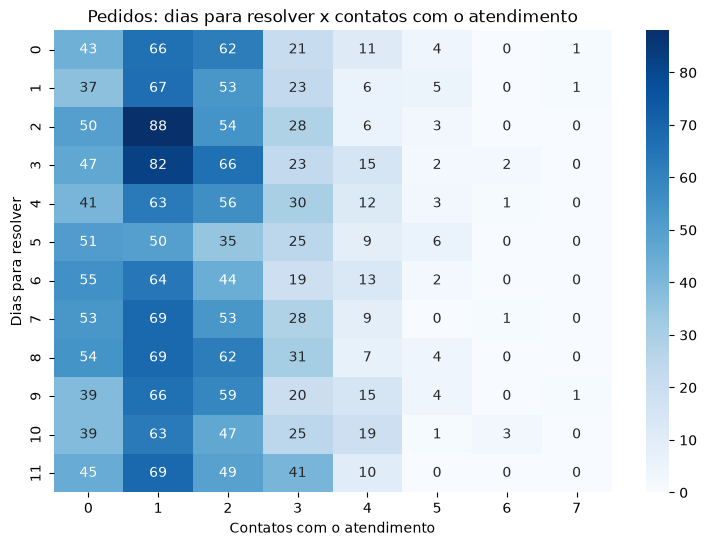

In [24]:
tabela_resolucao = pd.crosstab(df['resolution_time_days'], df['customer_service_contacts'])

plt.figure(figsize=(9, 6))
sns.heatmap(tabela_resolucao, annot=True, fmt="d", cmap="Blues")
plt.title('Pedidos: dias para resolver x contatos com o atendimento')
plt.xlabel('Contatos com o atendimento')
plt.ylabel('Dias para resolver')
plt.show()

In [25]:
sem_contato = df[df['customer_service_contacts'] == 0]
com_contato = df[df['customer_service_contacts'] > 0]

print('Zero contatos e tempo de resolução > 0:', (sem_contato['resolution_time_days'] > 0).sum())
print('Com contato e tempo de resolução == 0:', (com_contato['resolution_time_days'] == 0).sum())

Zero contatos e tempo de resolução > 0: 511
Com contato e tempo de resolução == 0: 165


**O que olhar:** com zero contatos, não houve problema levado ao atendimento. O esperado é tempo de resolução zero, ou quase nenhum pedido, na primeira coluna.

**Observação:** há 511 pedidos com zero contatos e tempo de resolução maior que zero, a primeira coluna está preenchida em quase todas as linhas. Há também 165 pedidos com contato e tempo de resolução zero. Isso confirma o que a seção 6 mostrou: o tempo de resolução se espalha igualmente, sem relação visível com o número de contatos. Não fica claro o que `resolution_time_days` mede quando não houve contato.


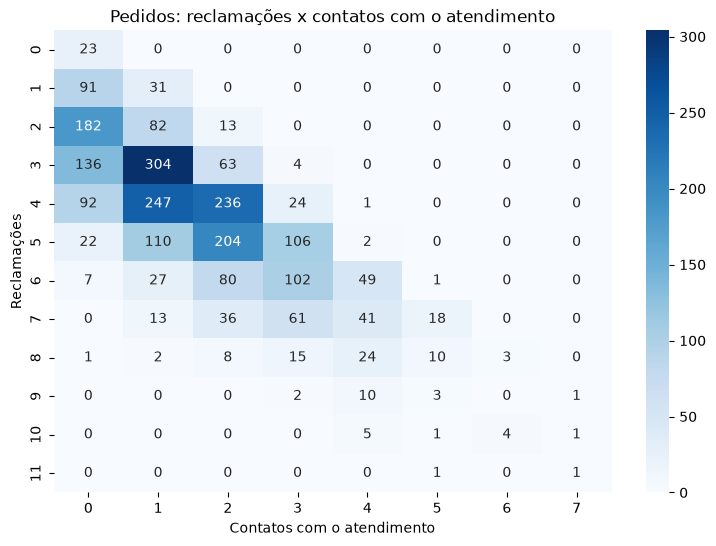

In [26]:
tabela_reclamacoes = pd.crosstab(df['complaints_count'], df['customer_service_contacts'])

plt.figure(figsize=(9, 6))
sns.heatmap(tabela_reclamacoes, annot=True, fmt="d", cmap="Blues")
plt.title('Pedidos: reclamações x contatos com o atendimento')
plt.xlabel('Contatos com o atendimento')
plt.ylabel('Reclamações')
plt.show()

In [27]:
print('Pedidos em que reclamações == contatos:', (df['complaints_count'] == df['customer_service_contacts']).sum())
print('Pedidos em que reclamações  > contatos:', (df['complaints_count'] > df['customer_service_contacts']).sum())
print('Pedidos em que reclamações  < contatos:', (df['complaints_count'] < df['customer_service_contacts']).sum())

Pedidos em que reclamações == contatos: 72
Pedidos em que reclamações  > contatos: 2428
Pedidos em que reclamações  < contatos: 0


**O que olhar:** o dicionário de dados define `complaints_count` como reclamações registradas pelo cliente, e `customer_service_contacts` como contatos com o atendimento. O dicionário não diz que toda reclamação passa pelo atendimento. Não há uma expectativa clara, só pela definição, sobre qual dos dois deveria ser maior.

**Observação:** em nenhum dos 2.500 pedidos o número de contatos passa o de reclamações. Em 72 pedidos os dois são iguais, e nos outros 2.428 há mais reclamações do que contatos. Se as duas colunas fossem independentes, seria esperado encontrar ao menos alguns pedidos com mais contatos que reclamações, mas isso nunca acontece.

**Decisão:** o projeto adota como premissa de trabalho que `complaints_count` inclui os contatos de `customer_service_contacts` somados a reclamações por outros canais, não cobertos por essa segunda coluna. É uma suposição, não uma confirmação do dicionário de dados. Fica registrada aqui para ser retomada na etapa de modelagem, onde usar as duas colunas como variáveis independentes arriscaria contar a mesma informação duas vezes.


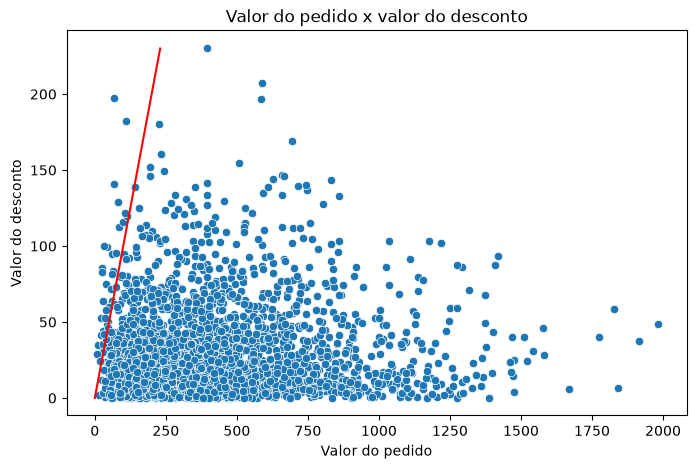

In [28]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='order_value', y='discount_value')
plt.plot([0, 230], [0, 230], color='red')
plt.title('Valor do pedido x valor do desconto')
plt.xlabel('Valor do pedido')
plt.ylabel('Valor do desconto')
plt.show()

In [29]:
pedidos_desconto_maior = df[df['discount_value'] > df['order_value']]

print('Pedidos com desconto maior que o valor do pedido:', len(pedidos_desconto_maior))
print('Valor do pedido máximo nesses casos:', pedidos_desconto_maior['order_value'].max())
print('Desconto máximo nesses casos:', pedidos_desconto_maior['discount_value'].max())

Pedidos com desconto maior que o valor do pedido: 35
Valor do pedido máximo nesses casos: 112.19
Desconto máximo nesses casos: 197.6


**O que olhar:** a linha vermelha marca desconto igual ao valor do pedido. Pontos acima dela são pedidos com desconto maior que o próprio valor.

**Observação:** 35 pedidos ficam acima da linha vermelha, com desconto maior que o valor do pedido. São pedidos de valor baixo, até 112,2, com desconto de até 197,6. Pode ser cupom, crédito ou erro, mas a base não permite confirmar.

**Decisão:** manter os dados como estão. Estas dúvidas entram nas limitações do projeto.


## 9. Quais variáveis andam junto com a nota de NPS?
**Por que importa:** responde à pergunta do enunciado sobre os fatores mais críticos para a satisfação.

**Atenção:** a medida usada é a correlação de Pearson (`.corr()`), que mede relação em linha reta. É um primeiro olhar, não uma prova. Correlação não é causa. Nas cores, vermelho indica relação positiva, as duas sobem juntas. Azul indica relação negativa, uma sobe e a outra desce.


In [30]:
colunas_numericas = [
    'customer_age', 'customer_tenure_months', 'order_value', 'items_quantity',
    'discount_value', 'payment_installments', 'delivery_time_days',
    'delivery_delay_days', 'freight_value', 'delivery_attempts',
    'customer_service_contacts', 'resolution_time_days', 'complaints_count',
    'repeat_purchase_30d', 'csat_internal_score', 'nps_score'
]

df[colunas_numericas].corr()['nps_score']

customer_age                -0.009936
customer_tenure_months      -0.009711
order_value                  0.036990
items_quantity               0.011468
discount_value               0.025104
payment_installments         0.023718
delivery_time_days           0.000925
delivery_delay_days         -0.597260
freight_value               -0.041087
delivery_attempts            0.027680
customer_service_contacts   -0.350845
resolution_time_days        -0.191392
complaints_count            -0.496800
repeat_purchase_30d          0.570324
csat_internal_score          0.563952
nps_score                    1.000000
Name: nps_score, dtype: float64

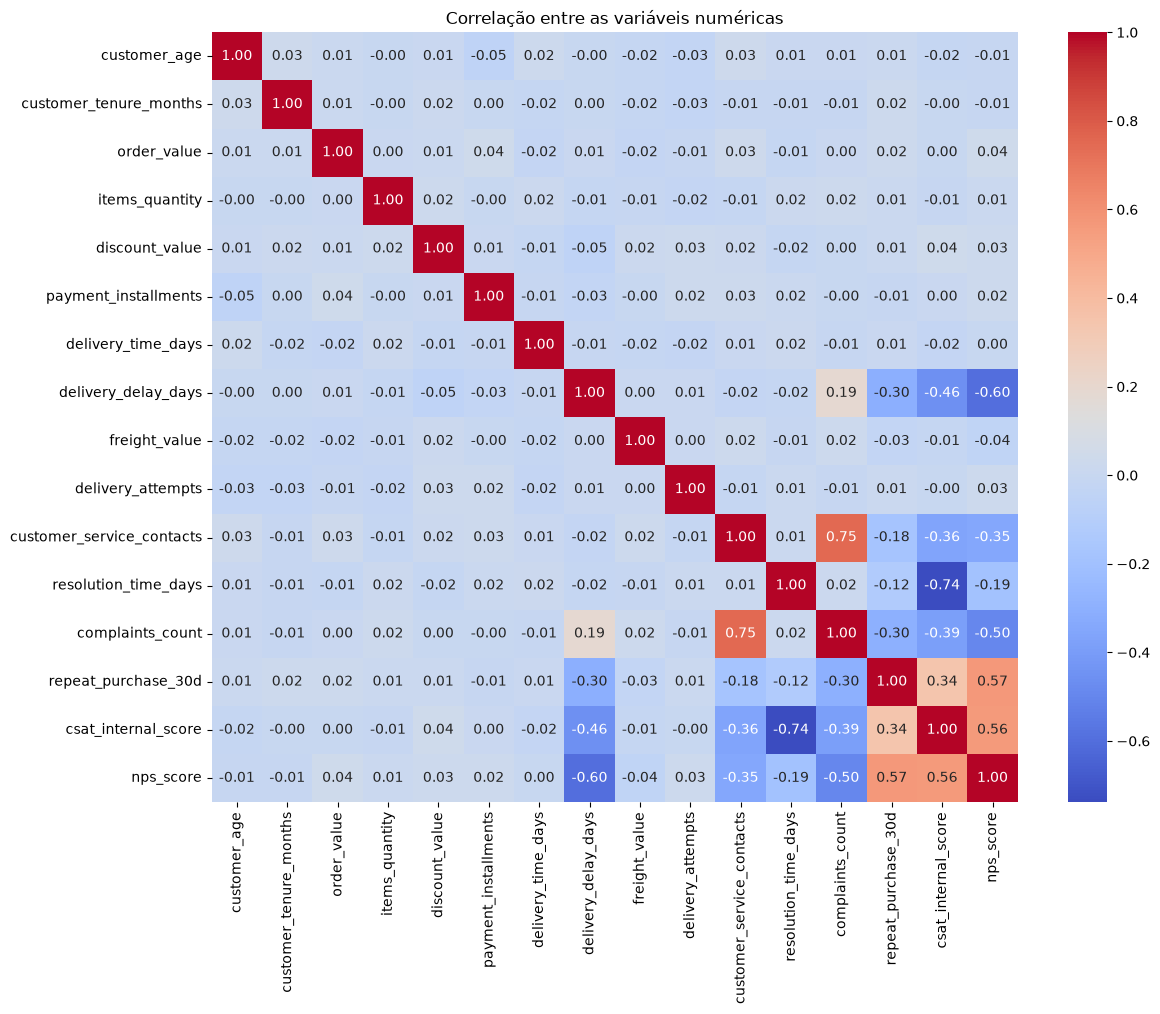

In [31]:
plt.figure(figsize=(13, 10))
sns.heatmap(df[colunas_numericas].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title('Correlação entre as variáveis numéricas')
plt.show()

**Observação:** as variáveis com relação mais forte com a nota de NPS são `delivery_delay_days` (-0,60), `complaints_count` (-0,50), `customer_service_contacts` (-0,35) e `resolution_time_days` (-0,19), todas negativas. `repeat_purchase_30d` (0,57) e `csat_internal_score` (0,56) têm relação positiva. Valor do pedido, desconto, frete, idade, tempo de casa, parcelas, itens, tentativas de entrega e o prazo estimado de entrega ficam perto de zero, entre -0,04 e 0,04.

**Hipótese:** os fatores que mais acompanham a nota são o atraso e o atendimento, reclamações e contatos. Quanto mais atraso, reclamações ou contatos, menor a nota. O atraso pesa muito, e o prazo estimado não pesa nada (0,00). O cliente parece reagir a receber depois do prometido, não a um prazo longo em si. Variáveis de compra, valor, desconto, frete, quase não acompanham a nota.

**Cuidado com duas colunas:** `csat_internal_score` e `repeat_purchase_30d` aparecem fortemente ligadas ao NPS, mas não sabemos quando são medidas. Se forem medidas junto da resposta de NPS ou depois dela, usá-las para prever o NPS seria usar a resposta para adivinhar a resposta, um vazamento de informação. Decisão: ficam fora do modelo e entram aqui só como associação.

**Limite da hipótese:** que alguma variável causa o NPS, nem que relações em curva ou em degrau foram capturadas. A correlação de Pearson só vê relações em linha reta.


## 10. Tempo real de entrega (prazo + atraso)
**Por que importa:** com a leitura de prazo estimado mais atraso, o tempo que o cliente realmente esperou é a soma das duas colunas. A pergunta é: a nota acompanha mais o tempo de espera total, ou o quanto a entrega passou do prometido?


In [32]:
df['tempo_real_entrega_dias'] = df['delivery_time_days'] + df['delivery_delay_days']

df['tempo_real_entrega_dias'].describe()

count    2500.000000
mean       10.209200
std         4.032262
min         2.000000
25%         7.000000
50%        10.000000
75%        13.000000
max        22.000000
Name: tempo_real_entrega_dias, dtype: float64

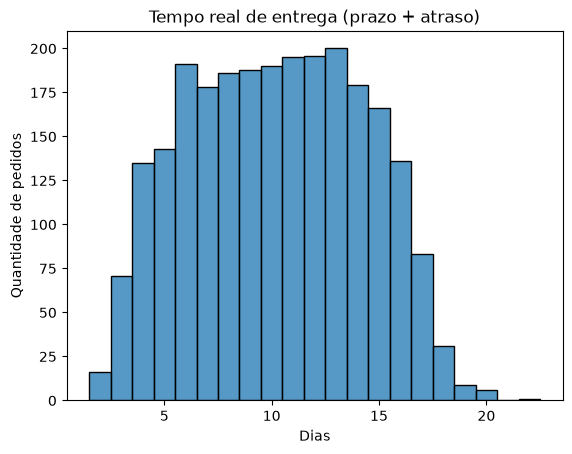

In [33]:
sns.histplot(data=df, x='tempo_real_entrega_dias', discrete=True)
plt.title('Tempo real de entrega (prazo + atraso)')
plt.xlabel('Dias')
plt.ylabel('Quantidade de pedidos')
plt.show()

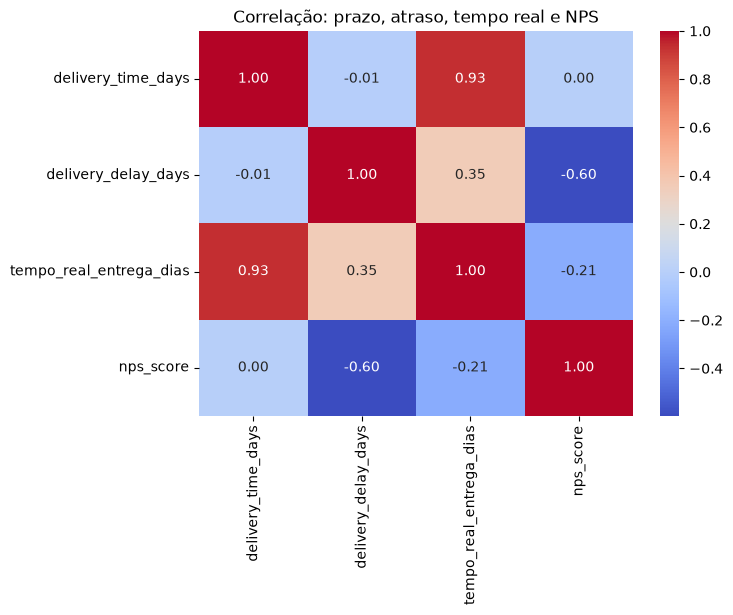

In [34]:
colunas_entrega = ['delivery_time_days', 'delivery_delay_days', 'tempo_real_entrega_dias', 'nps_score']

plt.figure(figsize=(7, 5))
sns.heatmap(df[colunas_entrega].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title('Correlação: prazo, atraso, tempo real e NPS')
plt.show()

In [35]:
df.groupby('delivery_time_days')['delivery_delay_days'].mean()

delivery_time_days
2     2.211823
3     2.273224
4     2.196078
5     2.169399
6     2.170330
7     2.109290
8     2.183168
9     2.157068
10    2.146067
11    2.279570
12    2.284444
13    1.972973
14    2.251282
Name: delivery_delay_days, dtype: float64

In [36]:
df.groupby('tempo_real_entrega_dias')['nps_score'].describe()

,count,mean,std,min,25%,50%,75%,max
tempo_real_entrega_dias,,,,,,,,
2,16.0,6.906250,2.080535,4.4,5.150,6.30,9.125,10.0
3,71.0,5.945070,2.202582,1.1,4.150,5.90,7.600,10.0
4,135.0,5.227407,2.271347,0.0,3.900,5.20,6.800,10.0
5,143.0,4.976224,2.442809,0.0,3.200,4.90,6.700,10.0
6,191.0,4.517801,2.377039,0.0,2.650,4.60,6.150,10.0
7,178.0,4.465730,2.373775,0.0,2.800,4.35,6.075,10.0
8,186.0,4.689247,2.641640,0.0,2.700,4.90,6.600,10.0
9,188.0,4.400000,2.539948,0.0,2.700,4.50,6.000,10.0
10,190.0,4.229474,2.475034,0.0,2.525,4.30,6.000,10.0


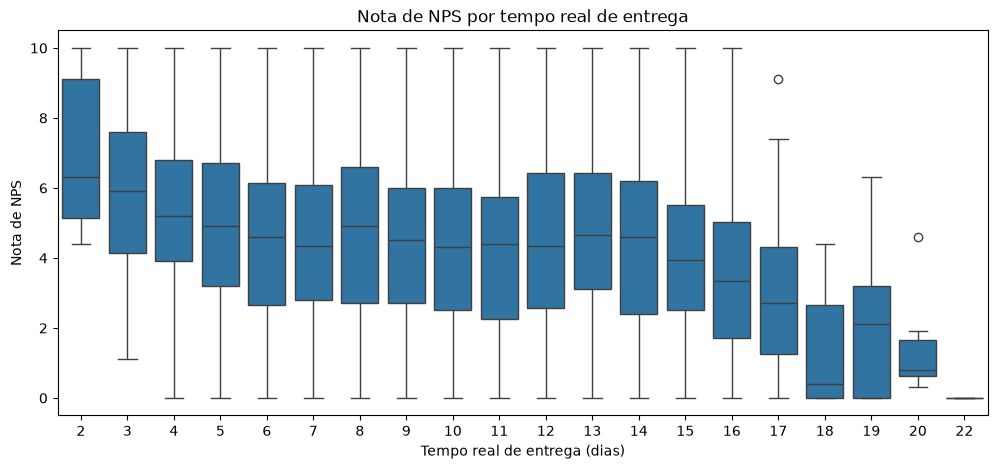

In [37]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x='tempo_real_entrega_dias', y='nps_score')
plt.title('Nota de NPS por tempo real de entrega')
plt.xlabel('Tempo real de entrega (dias)')
plt.ylabel('Nota de NPS')
plt.show()

**Observação:** o tempo real de entrega (prazo estimado mais atraso) vai de 2 a 22 dias, com mediana 10.

Comparando as três variáveis de prazo e sua correlação com a nota de NPS:
- atraso sozinho: -0,60, a que mais pesa
- tempo real, prazo mais atraso somados: -0,21, pesa bem menos
- prazo sozinho: 0,00, não pesa nada

Prazo e atraso não andam juntos. A correlação entre os dois é -0,01. Os números confirmam isso: a média de atraso fica entre 1,97 e 2,28 dias em todos os prazos, de 2 a 14. O prazo prometido ser curto ou longo não muda o atraso médio.

Olhando agora a nota de NPS por tempo real de entrega, não mais a correlação, mas a mediana em cada valor: ela é mais alta nos tempos curtos (6,3 com 2 dias, apenas 16 pedidos, 5,9 com 3 dias, 5,2 com 4 dias). Fica estável entre 4,3 e 4,9 de 5 a 14 dias, e cai a partir de 15 dias (3,95 com 15 dias, 2,7 com 17 dias). Acima de 18 dias há poucos pedidos na base, 9, 6 e 1, então essa ponta final é menos confiável.

**Hipótese:** o tempo real acompanha a nota bem menos que o atraso sozinho. Juntar prazo com atraso numa única variável dilui o sinal, porque o prazo não carrega informação útil e só atrapalha. A parte do tempo real que pesa na nota é o atraso. Um pedido de 12 dias que chegou no prazo tende a ter nota melhor que um de 6 dias que atrasou. As duas pontas do boxplot, tempos muito curtos e tempos acima de 15 dias, provavelmente vêm do atraso, não do prazo: tempos curtos só acontecem com pouco ou nenhum atraso, e tempos longos só acontecem com atraso alto. Para o modelo, isso indica usar o atraso como variável, não o tempo real somado.

**Limite da hipótese:** que o cliente não se importa com prazos longos. A base não mostra se o cliente escolheu o prazo, nem se pagou menos frete por um prazo maior.


## 11. Existe um "ponto de ruptura" na experiência do cliente?
**Por que importa:** o enunciado pergunta se há um ponto a partir do qual o NPS cai de forma marcante. A nota é cruzada com a quantidade de dias de atraso, de reclamações e de contatos. A coluna `count` mostra quantos pedidos há em cada valor. Valores com poucos pedidos merecem desconfiança.


In [38]:
df.groupby('delivery_delay_days')['nps_score'].describe()

,count,mean,std,min,25%,50%,75%,max
delivery_delay_days,,,,,,,,
0,277.0,6.856679,2.013667,1.1,5.5,6.80,8.5,10.0
1,615.0,5.546179,2.184379,0.0,4.1,5.50,7.0,10.0
2,646.0,4.580186,2.039770,0.0,3.1,4.60,6.0,10.0
3,525.0,3.436762,1.998215,0.0,2.1,3.40,4.8,9.4
4,270.0,2.444444,1.831272,0.0,0.9,2.30,3.6,8.3
5,116.0,1.481034,1.598962,0.0,0.0,1.25,2.4,6.3
6,34.0,1.097059,1.243281,0.0,0.0,0.70,1.9,4.6
7,14.0,0.292857,0.415959,0.0,0.0,0.00,0.6,1.1
8,3.0,0.000000,0.000000,0.0,0.0,0.00,0.0,0.0


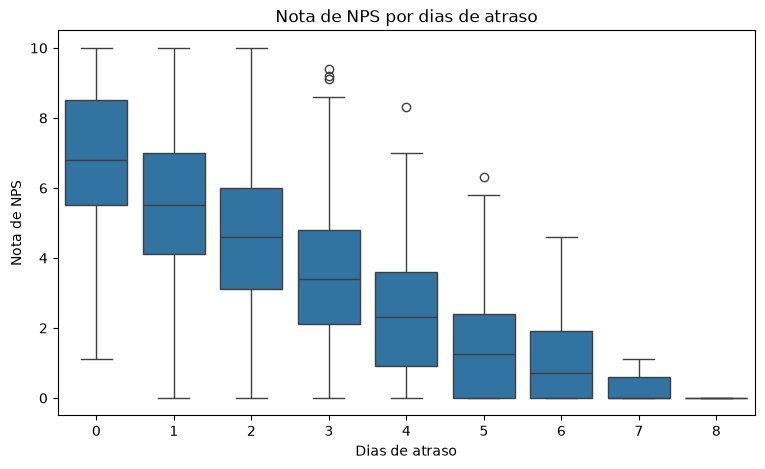

In [39]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='delivery_delay_days', y='nps_score')
plt.title('Nota de NPS por dias de atraso')
plt.xlabel('Dias de atraso')
plt.ylabel('Nota de NPS')
plt.show()

In [40]:
df.groupby('complaints_count')['nps_score'].describe()

,count,mean,std,min,25%,50%,75%,max
complaints_count,,,,,,,,
0,23.0,8.517391,1.306853,6.0,7.800,8.70,10.000,10.0
1,122.0,7.770492,1.308503,4.1,6.800,7.60,8.800,10.0
2,277.0,6.052347,2.261677,0.0,4.700,6.40,7.400,10.0
3,507.0,4.910059,2.282230,0.0,3.500,4.90,6.500,10.0
4,600.0,4.219167,2.242744,0.0,2.700,4.30,5.600,10.0
5,444.0,3.645270,2.138511,0.0,2.100,3.70,5.300,9.6
6,266.0,3.062030,1.911501,0.0,1.800,3.00,4.475,8.0
7,169.0,2.813609,2.160961,0.0,1.000,2.60,4.600,8.3
8,63.0,2.065079,1.771382,0.0,0.050,2.30,3.450,5.7


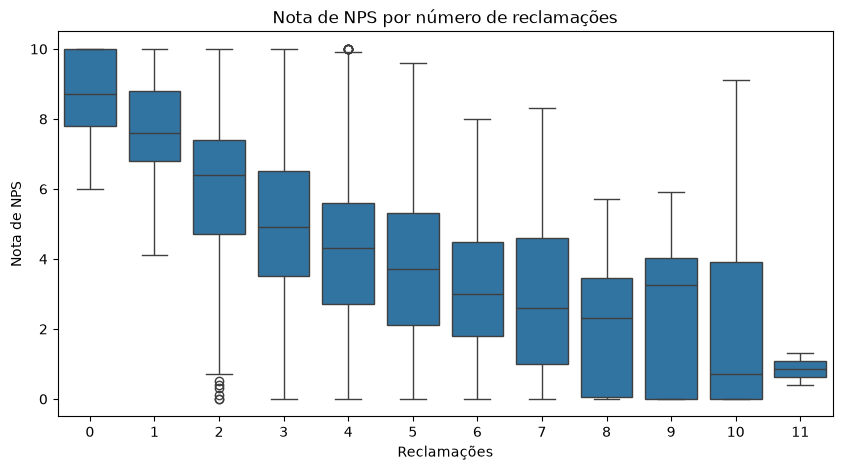

In [41]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='complaints_count', y='nps_score')
plt.title('Nota de NPS por número de reclamações')
plt.xlabel('Reclamações')
plt.ylabel('Nota de NPS')
plt.show()

In [42]:
df.groupby('customer_service_contacts')['nps_score'].describe()

,count,mean,std,min,25%,50%,75%,max
customer_service_contacts,,,,,,,,
0,554.0,5.543502,2.399473,0.0,3.90,5.50,7.200,10.0
1,816.0,4.657108,2.431036,0.0,2.90,4.70,6.400,10.0
2,640.0,4.116406,2.307278,0.0,2.50,4.10,5.700,10.0
3,314.0,3.201911,2.270353,0.0,1.50,2.90,4.700,10.0
4,132.0,2.654545,2.167468,0.0,0.45,2.60,4.250,9.1
5,34.0,2.238235,1.958666,0.0,0.10,2.45,3.675,7.0
6,7.0,0.742857,1.749149,0.0,0.00,0.00,0.250,4.7
7,3.0,1.200000,1.743560,0.0,0.20,0.40,1.800,3.2


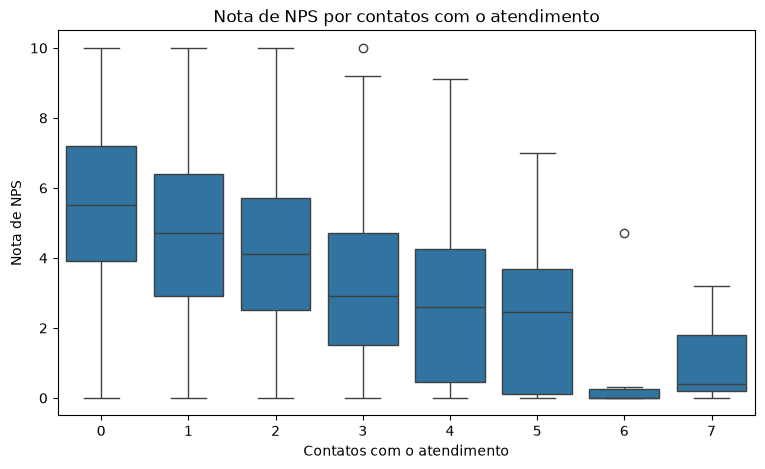

In [43]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='customer_service_contacts', y='nps_score')
plt.title('Nota de NPS por contatos com o atendimento')
plt.xlabel('Contatos com o atendimento')
plt.ylabel('Nota de NPS')
plt.show()

In [44]:
nota_arredondada = df['nps_score'].round()
df['is_detrator'] = (nota_arredondada <= 6).astype(int)

tabela_detratores = df.groupby('delivery_delay_days')['is_detrator'].agg(['mean', 'count'])
tabela_detratores['pct_detratores'] = (tabela_detratores['mean'] * 100).round(1)
print(tabela_detratores[['pct_detratores', 'count']])


                     pct_detratores  count
delivery_delay_days                       
0                              45.1    277
1                              66.8    615
2                              83.1    646
3                              94.1    525
4                              98.9    270
5                             100.0    116
6                             100.0     34
7                             100.0     14
8                             100.0      3


A mediana por dia de atraso já mostra a queda. Em porcentagem de detratores por dia, o ponto de ruptura fica mais direto de comunicar para um gestor: 45,1% dos pedidos sem atraso já são de clientes detratores, subindo para 66,8% com 1 dia, 83,1% com 2 dias, 94,1% com 3 dias e 98,9% com 4 dias. A partir de 5 dias, 100% dos pedidos são de detratores (poucos casos, 116 ou menos).


**Observação:** a mediana da nota cai a cada dia de atraso: 6,8 sem atraso, 5,5 com 1 dia, 4,6 com 2, 3,4 com 3, 2,3 com 4 e 1,25 com 5 dias. Com 6 dias ou mais há poucos pedidos (34, 14 e 3). Nas reclamações, a mediana sai de 8,7 (0 reclamações, só 23 pedidos) e 7,6 (1) para 6,4 (2) e 4,9 (3), e continua caindo mais devagar depois disso. Nos contatos, a mediana vai de 5,5 (nenhum contato) a 2,9 (3 contatos), e com 6 ou 7 contatos há só 10 pedidos.

**Hipótese:** no atraso, a queda é contínua, cerca de 1 ponto por dia, sem um degrau único. Cada dia a mais pesa. Por volta de 3 dias de atraso a mediana já fica abaixo de 4, e a partir de 5 dias fica perto de zero. Nas reclamações, a queda é mais forte nas primeiras (de 0 a 3) e suaviza depois. Os valores com poucos pedidos, atraso de 6 a 8 dias, 9 ou mais reclamações, 6 ou mais contatos, não sustentam conclusões.

**Limite da hipótese:** que o ponto indicado é o mesmo para todos os clientes, nem que reduzir o atraso até esse ponto eleva o NPS. Confirmar isso exige um experimento, como um teste A/B.


## 12. Pricing e perfil do cliente pesam na nota?
**Por que importa:** o enunciado pergunta que tipo de cliente tende a ter NPS mais alto ou mais baixo, e cita pricing como exemplo de área a investigar. A seção 9 já mostrou essas variáveis perto de zero na correlação geral com a nota. Aqui elas recebem um olhar dedicado, com gráfico próprio.


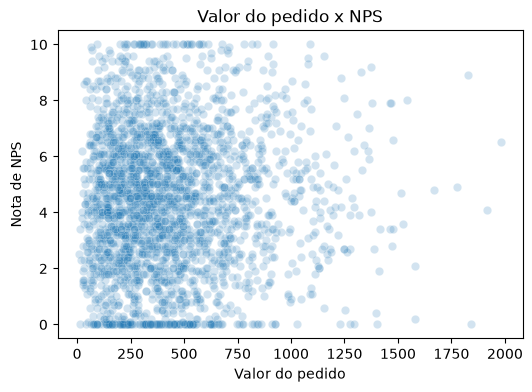

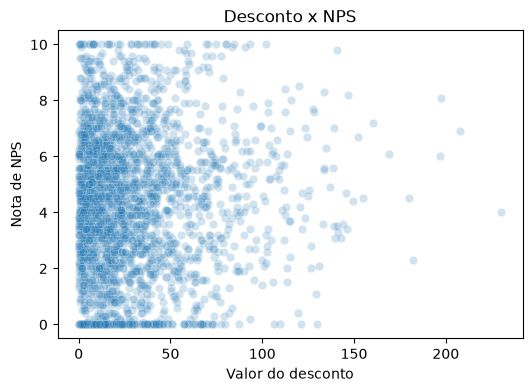

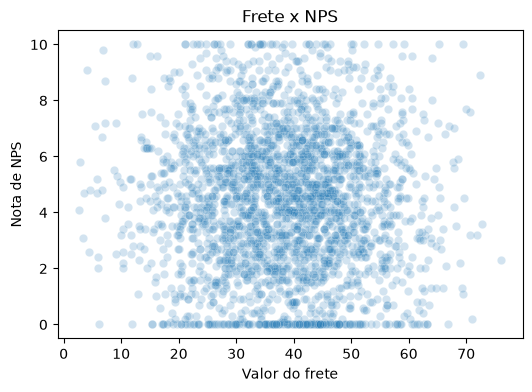

In [45]:
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='order_value', y='nps_score', alpha=0.2)
plt.title('Valor do pedido x NPS')
plt.xlabel('Valor do pedido')
plt.ylabel('Nota de NPS')
plt.show()

plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='discount_value', y='nps_score', alpha=0.2)
plt.title('Desconto x NPS')
plt.xlabel('Valor do desconto')
plt.ylabel('Nota de NPS')
plt.show()

plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='freight_value', y='nps_score', alpha=0.2)
plt.title('Frete x NPS')
plt.xlabel('Valor do frete')
plt.ylabel('Nota de NPS')
plt.show()


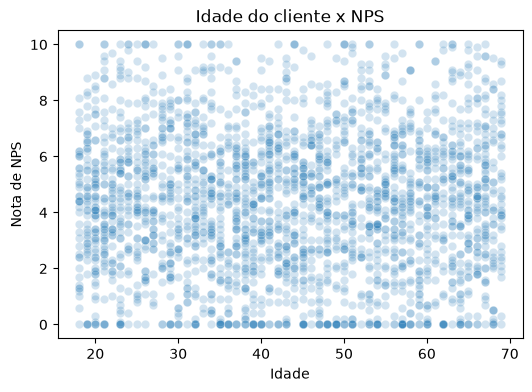

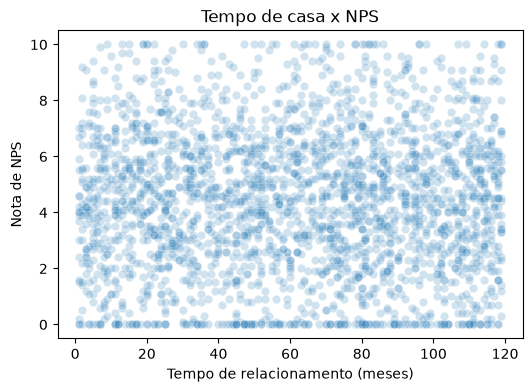

In [46]:
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='customer_age', y='nps_score', alpha=0.2)
plt.title('Idade do cliente x NPS')
plt.xlabel('Idade')
plt.ylabel('Nota de NPS')
plt.show()

plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='customer_tenure_months', y='nps_score', alpha=0.2)
plt.title('Tempo de casa x NPS')
plt.xlabel('Tempo de relacionamento (meses)')
plt.ylabel('Nota de NPS')
plt.show()


In [47]:
colunas_pricing_perfil = ['order_value', 'discount_value', 'freight_value', 'customer_age', 'customer_tenure_months', 'nps_score']

print('Correlação de cada variável com a nota de NPS:')
print(df[colunas_pricing_perfil].corr()['nps_score'])


Correlação de cada variável com a nota de NPS:
order_value               0.036990
discount_value            0.025104
freight_value            -0.041087
customer_age             -0.009936
customer_tenure_months   -0.009711
nps_score                 1.000000
Name: nps_score, dtype: float64


**Observação:** nos gráficos, os pontos formam uma nuvem espalhada, sem inclinação visível, em nenhuma das 5 variáveis. As correlações confirmam: valor do pedido (0,037), desconto (0,025), frete (-0,041), idade (-0,010) e tempo de casa (-0,010), todas entre -0,04 e 0,04.

**Hipótese:** nesta base, pricing (valor do pedido, desconto, frete) e o perfil básico do cliente (idade, tempo de relacionamento) não explicam a variação da nota de NPS. O que pesa são os fatores operacionais já identificados na seção 9: atraso, reclamações e tempo de resolução.

**Limite da hipótese:** que pricing ou perfil do cliente nunca importam para a satisfação. Só que, nesta amostra e com relação linear, nenhuma das 5 variáveis mostra relação com a nota.


## 13. Resumo e pontos em aberto

**Decisões desta etapa**
- Os dados não são alterados. Estranhezas viram limitação.
- NPS da empresa: nota arredondada com `.round()` do pandas e faixas clássicas (0 a 6, 7 e 8, 9 e 10). Resultado: -74,1.
- `delivery_time_days` é lido como prazo estimado, e `delivery_delay_days` como dias além desse prazo, conforme esclarecimento no canal de dúvidas do Tech Challenge.
- `csat_internal_score` e `repeat_purchase_30d` ficam fora do modelo.
- Atendimento (contatos, reclamações, resolução) pode entrar no modelo, assumindo que é registrado antes da resposta de NPS.
- `complaints_count` é tratado como uma medida que inclui `customer_service_contacts` mais reclamações por outros canais, premissa de trabalho não confirmada pelo dicionário. Usar as duas colunas juntas no modelo precisa levar essa sobreposição em conta.
- Pricing e perfil básico do cliente não mostram relação com a nota.

**Pontos em aberto sobre os dados (limitações)**
1. Em alguns pedidos o desconto é maior que o valor do pedido.
2. Há pedidos sem contato com o atendimento que têm tempo de resolução, e pedidos com contato e resolução zero.
3. Não se sabe quando são medidos `csat_internal_score` e `repeat_purchase_30d`.
4. Não se sabe se o atendimento é registrado antes da resposta de NPS.

O alvo (nota de NPS prevista antes da pesquisa) e o modelo de regressão linear estão em [`02_modelagem.ipynb`](02_modelagem.ipynb).
